In [2]:
%load_ext autoreload
%autoreload 2

import numpy as np
import matplotlib.pyplot as plt
from src.utils import load_gray, load_rgb, make_step

In [3]:
for n in ["camera", "astronaut"]:
    g = load_gray(n)
    print(n, g.dtype, g.shape, g.min(), g.max())

camera float64 (512, 512) 0.0 255.0
astronaut float64 (512, 512) 0.0 255.0


In [4]:
s = make_step(100, 100, 0, 255, 10, 15)
print(s.shape)
print(s[0, 46:54])


(100, 100)
[  3.01141363   9.98519681   9.06569132 -10.70471655 264.93879608
 259.50202458 242.31370226 262.23439676]


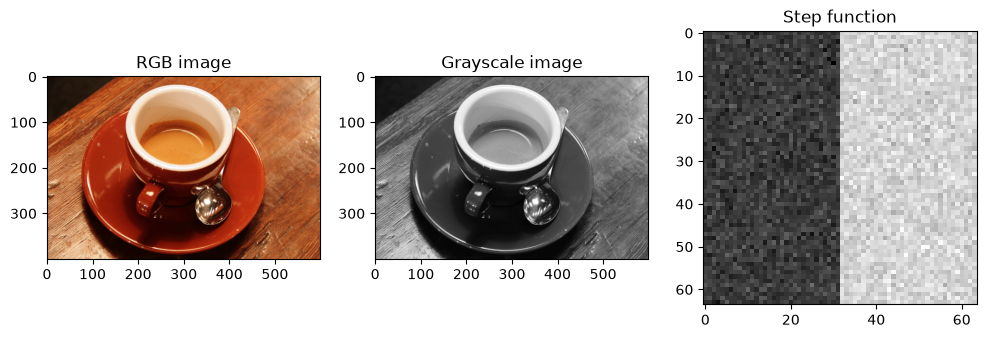

In [5]:
from src.utils import load_rgb, load_gray, make_step

colored = load_rgb("coffee")
convert_to_grey = load_gray("coffee")
step = make_step(64,64,0,100,10,0)

fig, ax = plt.subplots(1,3, figsize=(12,4))

ax[0].imshow(colored/255)   #without dividing by 255 showed the image as white with a little bit yellow
ax[0].set_title("RGB image")

ax[1].imshow(convert_to_grey, cmap="gray")
ax[1].set_title("Grayscale image")

ax[2].imshow(step, cmap="gray")
ax[2].set_title("Step function")

plt.show()

In [6]:
from src.bilateral import gaussian_kernel

print(np.round(gaussian_kernel(1, 1), 3))

k = gaussian_kernel(5, 11) # (σd, σr) = (5, 11)
print(k.shape, k[11, 11])
print(np.allclose(k, k.T), np.allclose(k, k[::-1, :])) #for symmetryic kernel, it should be equal to its transpose and also equal to its flipped version

m = gaussian_kernel(5)
print(m.shape)

[[0.368 0.607 0.368]
 [0.607 1.    0.607]
 [0.368 0.607 0.368]]
(23, 23) 1.0
True True
(21, 21)


In [7]:
from src.bilateral import bilateral_gray_naive
from src.utils import load_gray, make_step

input_image = make_step(64,64,0,100,10,0 )
output_image = bilateral_gray_naive(input_image, 5, 50, 11)

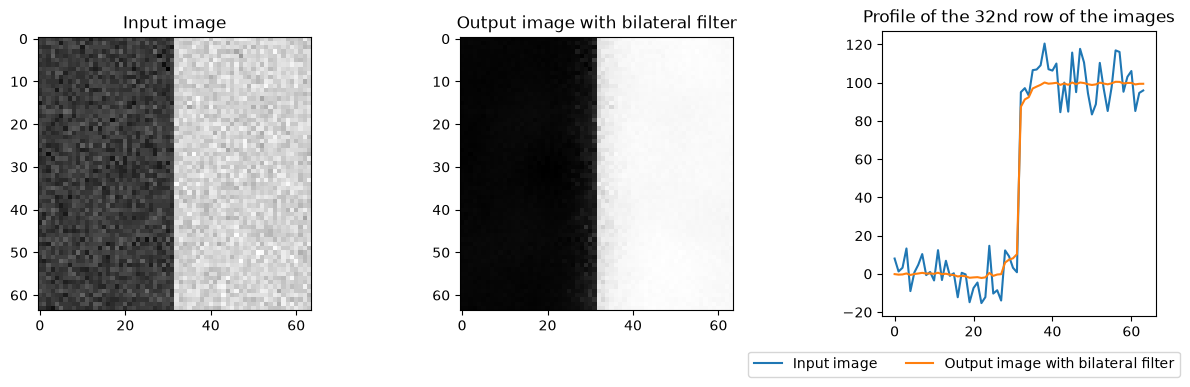

In [ ]:
fig, ax= plt.subplots(1,3, figsize=(12,4))
ax[0].imshow(input_image, cmap="gray")
ax[0].set_title("Input image")

ax[1].imshow(output_image, cmap="gray")
ax[1].set_title("Output image with bilateral filter")

ax[2].plot(input_image[32], label="Input image")
ax[2].plot(output_image[32], label="Output image with bilateral filter")
ax[2].legend(loc="upper center", bbox_to_anchor=(0.3,-0.1), ncol=2) #get helped from https://stackoverflow.com/questions/4700614/how-to-put-the-legend-out-of-the-plot
ax[2].set_title("Profile of the 32nd row of the images")

fig.tight_layout()
fig.savefig("docs/e1_figure1", dpi=150)
plt.show()

In [ ]:
# Test 2: The image should not change
# https://numpy.org/devdocs//reference/generated/numpy.allclose.html 
constant = np.full((20, 20), 80.0)
print(np.allclose(bilateral_gray_naive(constant, 2, 30), constant))

# Test 3 with allclose function: invarient to addition of a constant 
image_with_gaussnoise = make_step(64, 64, 0, 100, 10, 0) 
k = image_with_gaussnoise[:20, 28:35]
print(np.allclose(bilateral_gray_naive(k + 50, 2, 30),
                  bilateral_gray_naive(k, 2, 30) + 50))

True
True
